# Spike anomaly detection: cross-validation for macro-F1
Optimize anomaly-score aggregation and its threshold using five-fold cross-validation by trajectory. Freeze forecast model 1 (best checkpoint, epoch 20), evaluate all 200 fixed aggregation candidates, then fit the selected aggregation's threshold on all 1,000 development trajectories. The objective is **macro-F1 = (F1_normal + F1_spike)/2**, over classes rather than trajectories. There is no differentiable training loss in this search.

The original synthetic implementation in src/evaluate_AD.py used Adam on CrossEntropyLoss plus squared activated weights, binary anomaly-class F1 for validation, a fixed 0.5 threshold, and micro-F1 for reporting. Micro-F1 equals accuracy in this binary setting. Its loss interprets the batch axis as the class axis, and its best-score bookkeeping never updates. These motivate a direct macro-F1 search; this notebook runs the cross-validation workflow only.

Data: 1,000 development trajectories generated with seed 0, a separate 1,500-trajectory spike evaluation cohort with seed 1, and a 1,500-trajectory clean cohort. Missing datasets are generated from the project configurations in a local output folder without changing the dataset registry. All candidates share the same 371 evaluation timestamps (20-step forecast washout plus 5-step borders).

The current spike generator's time-range mask indexes the dimension axis, so spikes occur across the whole grid. Preserve that behavior for comparability and inspect empirical spike counts. Centered smoothing candidates are offline detectors, since they use future scores; the selected configuration has no smoothing.

Run top to bottom in the project interpreter. Outputs use the cv_ prefix under results/spike_macro_f1/. Local datasets and forecast-score caches are ignored by Git; delete the .npz caches before rerunning after changing generation or scoring code. The evaluation cohorts were inspected in earlier exploratory work, so the reported result is a follow-up evaluation, not fresh confirmation. Acceptance is correct fold separation and completed evaluation regardless of performance.


In [1]:
from pathlib import Path
import os, sys, json, copy, hashlib
import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from scipy.ndimage import convolve1d
from sklearn import metrics
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src/evaluate_AD.py').exists())
os.chdir(ROOT / 'src')
sys.path.insert(0, str(ROOT / 'src'))
import data_utils, evaluate_AD, models_synthetic, AD_modules
from configs import config
torch.set_num_threads(2)
torch.manual_seed(398)
np.random.seed(398)
OUT = ROOT / 'results/spike_macro_f1'
OUT.mkdir(exist_ok=True)
HORIZONS = [1,3,5,7,10,12,15,18,20]
print('Python:', sys.executable)
print('Output:', OUT)

MacBookAir-OK.local
SERVER=False
Python: /Users/fkrach/Code/GitRepos/Probabilistic_forecasting_for_Anomaly_Detection/.venv/bin/python
Output: /Users/fkrach/Code/GitRepos/Probabilistic_forecasting_for_Anomaly_Detection/results/spike_macro_f1


In [2]:
# Load exact matching saved datasets when available; otherwise generate without changing the registry.
def load_or_generate(config_name, seed):
    cfg = copy.deepcopy(getattr(config, config_name))
    cache = OUT / (config_name + '.npz')
    if cache.exists():
        with np.load(cache) as z:
            return z['paths'], z['labels'], json.loads(str(z['metadata']))
    overview, _ = data_utils.get_dataset_overview()
    match = overview[overview.description == json.dumps(cfg, sort_keys=True)]
    if len(match):
        row = match.iloc[-1]
        folder = ROOT / 'data/training_data' / (str(row['name']) + '-' + str(int(row['id'])))
        with open(folder / 'data.npy', 'rb') as f:
            paths = np.load(f); observed = np.load(f); counts = np.load(f); labels = np.load(f)
        metadata = json.loads((folder / 'metadata.txt').read_text())
        assert np.all(observed == 1), 'This experiment assumes the configured fully observed data.'
    else:
        np.random.seed(seed)
        generator = data_utils._STOCK_MODELS[cfg['model_name']](**cfg)
        paths, labels, _, _, dt, period = generator.generate_paths()
        metadata = dict(cfg, dt=dt, period=period, generation_seed=seed)
    np.savez_compressed(cache, paths=paths, labels=labels, metadata=json.dumps(metadata))
    return paths, labels, metadata

dev_paths, dev_labels, dev_meta = load_or_generate('AD_OrnsteinUhlenbeckWithSeason_spike_dict', 0)
print('Development shape:', dev_paths.shape)
print('Missing values:', np.isnan(dev_paths).sum(), 'dtype:', dev_paths.dtype)
print('Spike counts by time quartile:', [int(a.sum()) for a in np.array_split(dev_labels, 4, axis=2)])
print('Label prevalence:', np.unique(dev_labels, return_counts=True))
display(pd.DataFrame(dev_paths[:3, 0, :5]))

Development shape: (1000, 1, 401)
Missing values: 0 dtype: float64
Spike counts by time quartile: [516, 492, 535, 485]
Label prevalence: (array([0., 1.]), array([398972,   2028]))


,0,1,2,3,4
0,0.756781,0.770442,0.739819,0.748407,0.741643
1,0.756781,0.745018,0.740489,0.735365,0.733920
2,0.756781,0.773816,0.773775,0.771325,0.766098


In [3]:
# Forecast parameters and checkpoint remain fixed throughout optimization.
model_dir = ROOT / 'data/saved_models_AD_OrnsteinUhlenbeckWithSeason'
forecast_cfg = json.loads(pd.read_csv(model_dir / 'model_overview.csv').query('id == 1').iloc[0].description)
forecast_params, collate = evaluate_AD.get_forecast_model_param_dict(**forecast_cfg)
model = models_synthetic.NJODE(**forecast_params)
checkpoint_path = model_dir / 'id-1/best_checkpoint/checkpt.tar'
checkpoint = torch.load(checkpoint_path, map_location='cpu', weights_only=False)
model.load_state_dict(checkpoint['model_state_dict'])
model.eval()
checkpoint_hash = hashlib.sha256(checkpoint_path.read_bytes()).hexdigest()
torch.manual_seed(398)
replace_values = evaluate_AD.get_replace_forecast_values(model, forecast_cfg['data_dict'], collate, HORIZONS)
print('Forecast checkpoint epoch:', checkpoint['epoch'], 'sha256:', checkpoint_hash)
print('Replacement variances:', replace_values['var'])

def forecast_features(paths, metadata, cache_name, batch_size=100):
    cache = OUT / (cache_name + '_' + checkpoint_hash[:12] + '.npz')
    if cache.exists():
        with np.load(cache) as z:
            return z['scores'], z['valid']
    result = []
    common_valid = None
    for start in range(0, len(paths), batch_size):
        x = paths[start:start+batch_size]
        n, d, t = x.shape
        b = collate([dict(stock_path=x, observed_dates=np.ones((n,t), dtype=int),
                          nb_obs=np.full(n,t-1), dt=metadata['dt'])])
        with torch.no_grad():
            times, preds = model.custom_forward(
                b['times'], b['time_ptr'], b['X'], b['obs_idx'], metadata['dt'],
                metadata['maturity'], b['start_X'], b['n_obs_ot'], steps=HORIZONS,
                get_loss=False, M=b['M'], start_M=b['start_M'])
        moments = np.full((t,n,d,len(model.output_vars),len(HORIZONS)), np.nan, dtype=np.float32)
        grid = np.linspace(0, metadata['maturity'], t)
        for h in range(len(HORIZONS)):
            ids = np.flatnonzero(np.any(np.abs(grid[:,None] - np.asarray(times[h])[None,:]) < 1e-10, axis=1))
            y = preds[h].detach().cpu().numpy()
            for m in range(len(model.output_vars)):
                moments[ids,:,:,m,h] = y[:,:,m*d:(m+1)*d]
        valid = np.isfinite(moments).all(axis=(1,2,3,4))
        if common_valid is None:
            common_valid = valid
        assert np.array_equal(valid, common_valid)
        scorer = AD_modules.AD_module(model.output_vars, HORIZONS, replace_values=replace_values)
        scores = np.zeros((t,n,d,len(HORIZONS)), dtype=np.float32)
        scores[valid] = scorer.get_individual_scores(torch.tensor(moments[valid]), torch.tensor(x.transpose(2,0,1), dtype=torch.float32)[valid]).numpy()
        result.append(scores.transpose(1,0,2,3))
        print(cache_name, min(start+batch_size, len(paths)), '/', len(paths), flush=True)
    scores = np.concatenate(result)
    assert np.isfinite(scores).all()
    np.savez_compressed(cache, scores=scores, valid=common_valid)
    return scores, common_valid

dev_scores, valid = forecast_features(dev_paths, dev_meta, 'development')
# Match the original radius-5 evaluation domain for every candidate.
time_mask = valid.copy()
first_valid = np.flatnonzero(valid)[0]
time_mask[:first_valid+5] = False
time_mask[-5:] = False
assert time_mask.any()
labels = dev_labels.transpose(0,2,1).astype(int)
print('First valid forecast:', first_valid, 'common evaluation timestamps:', time_mask.sum())
print('Development label counts:', np.bincount(labels[:,time_mask].ravel(), minlength=2))

using loss: ad_var
neuralODE use input scaling with tanh
use residual network: input_size=150, output_size=3
Forecast checkpoint epoch: 20 sha256: 67778eb10d1a993f2b015f50b1eeb0e38e7bf886c6567316064cf8a2f592183f
Replacement variances: [[0.00075703 0.0005536  0.00056498 0.00096585 0.00164888 0.00206842
  0.00271179 0.00319283 0.00343223]]
First valid forecast: 20 common evaluation timestamps: 371
Development label counts: [369119   1881]


In [4]:
def report(y, pred):
    y, pred = y.ravel(), pred.ravel()
    tn, fp, fn, tp = metrics.confusion_matrix(y, pred, labels=[0,1]).ravel()
    f0, f1 = metrics.f1_score(y, pred, labels=[0,1], average=None, zero_division=0)
    return dict(macro_f1=(f0+f1)/2, micro_f1=metrics.f1_score(y,pred,average='micro'),
                normal_f1=f0, spike_f1=f1,
                spike_precision=metrics.precision_score(y,pred,zero_division=0),
                spike_recall=metrics.recall_score(y,pred,zero_division=0),
                TN=int(tn), FP=int(fp), FN=int(fn), TP=int(tp))

def best_threshold(y, scores):
    # Exact search over distinct scores with the original strict score > threshold rule.
    y, scores = y.ravel().astype(int), scores.ravel()
    assert np.isfinite(scores).all() and set(np.unique(y)) == {0,1}
    order = np.argsort(-scores, kind='stable')
    s, target = scores[order], y[order]
    ends = np.r_[np.flatnonzero(s[:-1] != s[1:]), len(s)-1]
    k = np.r_[0, ends+1]
    tp = np.r_[0, np.cumsum(target)[ends]]
    fp = k-tp; fn = target.sum()-tp; tn = len(y)-target.sum()-fp
    f1 = 2*tp / np.maximum(2*tp+fp+fn,1)
    f0 = 2*tn / np.maximum(2*tn+fp+fn,1)
    macro = (f0+f1)/2
    thresholds = np.r_[s[0], np.nextafter(s[ends], -np.inf)]
    i = int(np.argmax(macro))
    threshold = float(thresholds[i])
    # Cast to float64 so nextafter boundary comparisons do not round back to float32.
    assert np.isclose(report(y, scores.astype(float) > threshold)['macro_f1'], macro[i])
    return threshold, float(macro[i])

In [5]:
# Fixed search space: 80 structured candidates and 120 seeded random candidates.
def aggregate(features, weights, radius, tau):
    raw = np.einsum('ntdh,h->ntd', features, np.asarray(weights, dtype=np.float32))
    offsets = np.arange(-radius,radius+1)
    kernel = np.exp(-np.abs(offsets)/tau)
    kernel /= kernel.sum()
    return convolve1d(raw, kernel, axis=1, mode='constant')[:,time_mask].astype(float)

rng = np.random.default_rng(398)
candidates = []
for radius in [0,1,2,5]:
    for tau in [0.5,2.0]:
        for weights in [*np.eye(len(HORIZONS)), np.ones(len(HORIZONS))/len(HORIZONS)]:
            candidates.append(dict(radius=radius, tau=tau, weights=weights.tolist()))
for _ in range(120):
    weights = rng.dirichlet(np.full(len(HORIZONS),0.3))
    candidates.append(dict(radius=int(rng.choice([0,1,2,5])), tau=float(rng.choice([0.25,0.5,1.,2.,5.])), weights=weights.tolist()))

print('Candidate configurations:', len(candidates))
(OUT / 'cv_candidates.json').write_text(json.dumps(candidates, indent=2))

Candidate configurations: 200


51658

## Select aggregation by five-fold cross-validation
For each candidate and fold, maximize training-fold macro-F1 over all distinct score thresholds, then evaluate that unchanged threshold on held-out trajectories. Stratify trajectories by whether they contain an evaluated spike; timestamps of a trajectory never cross fold boundaries. Select the candidate with the highest mean held-out macro-F1 (tie: lower candidate ID).

Refit the selected candidate's threshold on all development trajectories before evaluating either external cohort. The final score is a normalized nonnegative horizon-weighted sum of Gaussian surprise, optionally smoothed by a normalized exponential temporal kernel. Threshold raw aggregated scores directly to avoid sigmoid saturation; the saved threshold is not a probability threshold for an unchanged AD_module.

The mean CV score is used for selection and is not an unbiased nested-CV performance estimate. Cross-validation here conditions on the frozen forecaster; it does not retrain that network. Bootstrap test intervals resample whole trajectories with fixed parameters and do not include selection or retraining uncertainty.


In [6]:
from sklearn.model_selection import StratifiedKFold
CV_SEED = 400
CV_FOLDS = 5
cv_labels = labels[:,time_mask].astype(int)
cv_has_spike = (cv_labels.sum(axis=(1,2)) > 0).astype(int)
assert len(candidates) == 200
assert np.isfinite(dev_scores).all() and set(np.unique(cv_labels)) == {0,1}
assert all(np.bincount(cv_has_spike) >= CV_FOLDS)
cv_splitter = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=CV_SEED)
cv_splits = list(cv_splitter.split(np.arange(len(cv_labels)),cv_has_spike))
cv_assignment = np.full(len(cv_labels),-1,dtype=int)
cv_fold_rows = []
for fold, (fit_ids, heldout_ids) in enumerate(cv_splits):
    assert not np.intersect1d(fit_ids,heldout_ids).size
    assert len(fit_ids)+len(heldout_ids) == len(cv_labels)
    assert (cv_assignment[heldout_ids] == -1).all()
    cv_assignment[heldout_ids] = fold
    assert set(np.unique(cv_labels[fit_ids])) == {0,1}
    assert set(np.unique(cv_labels[heldout_ids])) == {0,1}
    cv_fold_rows.append(dict(fold=fold,fit_paths=len(fit_ids),heldout_paths=len(heldout_ids),
                             fit_spikes=int(cv_labels[fit_ids].sum()),
                             heldout_spikes=int(cv_labels[heldout_ids].sum())))
assert (cv_assignment >= 0).all()
print('Development scores:',dev_scores.shape,'labels:',cv_labels.shape,
      'missing scores:',int(np.isnan(dev_scores).sum()))
print('Evaluated label counts:',np.bincount(cv_labels.ravel(),minlength=2))
display(pd.DataFrame(cv_fold_rows))
pd.DataFrame(dict(trajectory=np.arange(len(cv_labels)),fold=cv_assignment,
                  has_spike=cv_has_spike)).to_csv(OUT / 'cv_folds.csv',index=False)


Development scores: (1000, 401, 1, 9) labels: (1000, 371, 1) missing scores: 0
Evaluated label counts: [369119   1881]


,fold,fit_paths,heldout_paths,fit_spikes,heldout_spikes
0,0,800,200,1513,368
1,1,800,200,1503,378
2,2,800,200,1504,377
3,3,800,200,1540,341
4,4,800,200,1464,417


In [7]:
# Each score array is computed once; thresholds are fitted separately inside each fold.
cv_records = []
for candidate_id, candidate in enumerate(candidates):
    candidate_scores = aggregate(dev_scores, **candidate)
    for fold, (fit_ids, heldout_ids) in enumerate(cv_splits):
        fold_threshold, fit_f1 = best_threshold(cv_labels[fit_ids], candidate_scores[fit_ids])
        heldout_metrics = report(cv_labels[heldout_ids],candidate_scores[heldout_ids] > fold_threshold)
        cv_records.append(dict(candidate=candidate_id,fold=fold,threshold=fold_threshold,
                               fit_macro_f1=fit_f1,**heldout_metrics))
    if (candidate_id+1) % 20 == 0:
        print('CV candidates:',candidate_id+1,'/',len(candidates),flush=True)
cv_fold_results = pd.DataFrame(cv_records)
assert len(cv_fold_results) == len(candidates)*CV_FOLDS
cv_ranking = cv_fold_results.groupby('candidate',as_index=False).agg(
    mean_macro_f1=('macro_f1','mean'),std_macro_f1=('macro_f1','std'),
    min_macro_f1=('macro_f1','min'),mean_spike_f1=('spike_f1','mean'),
    mean_spike_precision=('spike_precision','mean'),mean_spike_recall=('spike_recall','mean')
).sort_values(['mean_macro_f1','candidate'],ascending=[False,True]).reset_index(drop=True)
cv_candidate_id = int(cv_ranking.iloc[0].candidate)
cv_aggregation = copy.deepcopy(candidates[cv_candidate_id])
cv_dev_scores = aggregate(dev_scores, **cv_aggregation)
cv_threshold, cv_refit_macro = best_threshold(cv_labels,cv_dev_scores)
cv_selected = dict(**cv_aggregation,threshold=cv_threshold)
cv_oof_pred = np.zeros_like(cv_labels,dtype=bool)
for row in cv_fold_results[cv_fold_results.candidate == cv_candidate_id].itertuples():
    heldout_ids = cv_splits[int(row.fold)][1]
    cv_oof_pred[heldout_ids] = cv_dev_scores[heldout_ids] > row.threshold
cv_oof_metrics = report(cv_labels,cv_oof_pred)
cv_fold_results.to_csv(OUT / 'cv_fold_metrics.csv',index=False)
cv_ranking.to_csv(OUT / 'cv_candidate_ranking.csv',index=False)
cv_parameter_record = dict(
    **cv_selected,candidate_id=cv_candidate_id,horizons=HORIZONS,
    cv_seed=CV_SEED,cv_folds=CV_FOLDS,fold_assignment=cv_assignment.tolist(),
    selection_metric='mean held-out fold macro-F1, labels=[0,1]',
    mean_cv_macro_f1=float(cv_ranking.iloc[0].mean_macro_f1),
    std_cv_macro_f1=float(cv_ranking.iloc[0].std_macro_f1),
    refit_trajectories=len(cv_labels),refit_development_macro_f1=cv_refit_macro,
    candidate_list_sha256=hashlib.sha256(json.dumps(candidates,sort_keys=True).encode()).hexdigest(),
    checkpoint_sha256=checkpoint_hash,replacement_variances=replace_values['var'].tolist(),
    evaluation_timestamps=np.flatnonzero(time_mask).tolist(),
    threshold_fit='all development trajectories AFTER selecting aggregation by CV',
    decision_rule='aggregate > threshold',score_scale='raw Gaussian surprise',
    test_use='previously inspected test reused for follow-up evaluation')
# Freeze the selected configuration on disk before any test evaluation in this section.
(OUT / 'cv_selected_parameters.json').write_text(json.dumps(cv_parameter_record,indent=2))
print('Selected candidate:',cv_candidate_id)
print('Selected configuration:',cv_selected)
print('Mean fold macro-F1:',cv_parameter_record['mean_cv_macro_f1'])
print('Pooled out-of-fold macro-F1 (selection score):',cv_oof_metrics['macro_f1'])
print('Refitted development macro-F1 (in-sample):',cv_refit_macro)
display(cv_ranking.head(10).round(5))
display(cv_fold_results.query('candidate == @cv_candidate_id')[
    ['fold','threshold','fit_macro_f1','macro_f1','spike_f1','spike_precision','spike_recall']
].round(5))

CV candidates: 20 / 200
CV candidates: 40 / 200
CV candidates: 60 / 200
CV candidates: 80 / 200
CV candidates: 100 / 200
CV candidates: 120 / 200
CV candidates: 140 / 200
CV candidates: 160 / 200
CV candidates: 180 / 200
CV candidates: 200 / 200
Selected candidate: 159
Selected configuration: {'radius': 0, 'tau': 1.0, 'weights': [0.10094510644485205, 0.016365556460590926, 0.004294169638109042, 0.00019659729541592725, 0.6717778977129204, 0.0031603500266796864, 0.19762437629258175, 0.002043628380538213, 0.003592317748312112], 'threshold': 22.95992851257324}
Mean fold macro-F1: 0.7797274554779451
Pooled out-of-fold macro-F1 (selection score): 0.7776376707633952
Refitted development macro-F1 (in-sample): 0.7786866516206412


,candidate,mean_macro_f1,std_macro_f1,min_macro_f1,mean_spike_f1,mean_spike_precision,mean_spike_recall
0,159,0.77973,0.02526,0.75354,0.56148,0.64998,0.50101
1,193,0.77675,0.02703,0.75153,0.55541,0.70789,0.46293
2,198,0.76883,0.03073,0.73277,0.53963,0.71221,0.44050
3,123,0.76794,0.03330,0.72978,0.53783,0.72279,0.43525
4,111,0.76747,0.02543,0.75247,0.53734,0.55265,0.53893
5,163,0.76650,0.03133,0.72536,0.53486,0.78547,0.41156
6,160,0.76590,0.02951,0.73616,0.53377,0.70935,0.43334
7,182,0.76583,0.02974,0.72816,0.53354,0.77643,0.41220
8,115,0.76526,0.02969,0.72523,0.53239,0.78173,0.40898
9,83,0.76520,0.02863,0.72781,0.53227,0.77444,0.41010


,fold,threshold,fit_macro_f1,macro_f1,spike_f1,spike_precision,spike_recall
795,0,22.95311,0.77616,0.78815,0.57812,0.68015,0.50272
796,1,22.96081,0.77005,0.81752,0.63652,0.86758,0.50265
797,2,22.95808,0.78362,0.76061,0.52362,0.53297,0.51459
798,3,22.95993,0.77866,0.77882,0.55949,0.61922,0.51026
799,4,22.95993,0.78621,0.75354,0.50965,0.55000,0.47482


Spike test trajectories: 1500 label counts: [553733   2767]


,macro_f1,micro_f1,normal_f1,spike_f1,spike_precision,spike_recall,TN,FP,FN,TP
all_normal,0.49875,0.99503,0.99751,0.00000,0.00000,0.00000,553733.0,0.0,2767.0,0.0
cv_macro_optimized,0.80365,0.99682,0.99840,0.60889,0.78417,0.49765,553354.0,379.0,1390.0,1377.0


Clean test trajectories: 1500


,false_positive_rate
all_normal,0.000000
cv_macro_optimized,0.000386


,macro_f1,lower,upper
method,,,
all_normal,0.49875,0.49871,0.49880
cv_macro_optimized,0.80365,0.78962,0.81658


,macro_f1_difference,lower,upper
comparator,,,
all_normal,0.30489,0.29083,0.31782


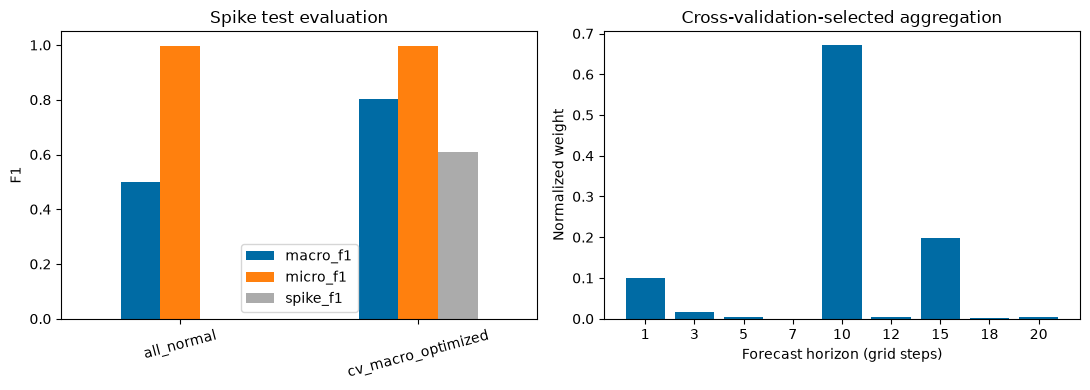

In [8]:
# Parameters have been frozen on disk; evaluation cohorts do not select them.
test_paths, test_labels, test_meta = load_or_generate('AD_OrnsteinUhlenbeckWithSeason_spike_dict_eval', 1)
test_scores, test_valid = forecast_features(test_paths, test_meta, 'test_spike')
assert np.array_equal(valid,test_valid)
test_y = test_labels.transpose(0,2,1).astype(int)[:,time_mask]
cv_test_scores = aggregate(test_scores,**cv_aggregation)
cv_test_pred = cv_test_scores > cv_threshold
cv_test_metrics = report(test_y,cv_test_pred)
cv_test_comparison = pd.DataFrame({
    'all_normal':report(test_y,np.zeros_like(test_y)),
    'cv_macro_optimized':cv_test_metrics
}).T
cv_test_comparison.to_csv(OUT / 'cv_test_comparison.csv')
print('Spike test trajectories:',len(test_paths),'label counts:',np.bincount(test_y.ravel(),minlength=2))
display(cv_test_comparison.round(5))

# No positive labels in the clean cohort: report false-positive rate.
clean_paths, clean_labels, clean_meta = load_or_generate('AD_OrnsteinUhlenbeckWithSeason_eval', 1)
clean_scores, clean_valid = forecast_features(clean_paths,clean_meta,'test_clean')
assert np.array_equal(valid,clean_valid) and not clean_labels.any()
cv_clean_scores = aggregate(clean_scores,**cv_aggregation)
cv_clean_fpr = float((cv_clean_scores > cv_threshold).mean())
cv_clean_comparison = pd.Series(
    {'all_normal':0.,'cv_macro_optimized':cv_clean_fpr},name='false_positive_rate')
cv_clean_comparison.to_csv(OUT / 'cv_clean_false_positive_rate.csv')
print('Clean test trajectories:',len(clean_paths))
display(cv_clean_comparison.to_frame())

# Paired bootstrap against the all-normal baseline; keep all times of each trajectory together.
def trajectory_counts(y,pred):
    axes = tuple(range(1,y.ndim))
    return np.stack([((y==0)&(~pred)).sum(axis=axes),
                     ((y==0)&pred).sum(axis=axes),
                     ((y==1)&(~pred)).sum(axis=axes),
                     ((y==1)&pred).sum(axis=axes)],axis=1)
def macro_from_counts(c):
    tn,fp,fn,tp = c.T
    return (2*tn/np.maximum(2*tn+fp+fn,1)+2*tp/np.maximum(2*tp+fp+fn,1))/2
cv_bootstrap_ids = np.random.default_rng(399).integers(0,len(test_y),size=(500,len(test_y)))
cv_bootstrap_values = {}
cv_interval_rows = []
for name,pred in {'all_normal':np.zeros_like(test_y,dtype=bool),
                   'cv_macro_optimized':cv_test_pred}.items():
    counts = trajectory_counts(test_y,pred)
    values = macro_from_counts(counts[cv_bootstrap_ids].sum(axis=1))
    cv_bootstrap_values[name] = values
    low,high = np.quantile(values,[.025,.975])
    cv_interval_rows.append(dict(method=name,macro_f1=cv_test_comparison.loc[name,'macro_f1'],
                                 lower=float(low),upper=float(high)))
cv_bootstrap_summary = pd.DataFrame(cv_interval_rows).set_index('method')
cv_bootstrap_summary.to_csv(OUT / 'cv_test_macro_f1_bootstrap.csv')
delta = cv_bootstrap_values['cv_macro_optimized']-cv_bootstrap_values['all_normal']
low,high = np.quantile(delta,[.025,.975])
cv_paired_differences = pd.DataFrame([dict(
    comparator='all_normal',
    macro_f1_difference=cv_test_metrics['macro_f1']-cv_test_comparison.loc['all_normal','macro_f1'],
    lower=float(low),upper=float(high))]).set_index('comparator')
cv_paired_differences.to_csv(OUT / 'cv_paired_macro_f1_differences.csv')
np.savez_compressed(OUT / 'cv_test_predictions.npz',labels=test_y,predictions=cv_test_pred,
                    development_oof_predictions=cv_oof_pred)
display(cv_bootstrap_summary.round(5))
display(cv_paired_differences.round(5))

cv_fig,cv_axes = plt.subplots(1,2,figsize=(11,4))
cv_test_comparison[['macro_f1','micro_f1','spike_f1']].plot.bar(ax=cv_axes[0],rot=15,ylim=(0,1.05))
cv_axes[0].set_title('Spike test evaluation')
cv_axes[0].set_ylabel('F1')
cv_axes[1].bar([str(h) for h in HORIZONS],cv_aggregation['weights'])
cv_axes[1].set_xlabel('Forecast horizon (grid steps)')
cv_axes[1].set_ylabel('Normalized weight')
cv_axes[1].set_title('Cross-validation-selected aggregation')
cv_fig.tight_layout()
cv_fig.savefig(OUT / 'cv_test_results.png',dpi=160,bbox_inches='tight')
plt.show()


In [9]:
# Verify saved parameters reproduce the detector and selected fold thresholds use only fit IDs.
cv_saved = json.loads((OUT / 'cv_selected_parameters.json').read_text())
assert cv_saved['candidate_id'] == int(cv_ranking.iloc[0].candidate)
assert cv_saved['fold_assignment'] == cv_assignment.tolist()
assert len(cv_fold_results) == 1000
for row in cv_fold_results.query('candidate == @cv_candidate_id').itertuples():
    fit_ids, heldout_ids = cv_splits[int(row.fold)]
    fitted_threshold, _ = best_threshold(cv_labels[fit_ids],cv_dev_scores[fit_ids])
    assert fitted_threshold == row.threshold
    np.testing.assert_array_equal(cv_oof_pred[heldout_ids],
                                  cv_dev_scores[heldout_ids] > fitted_threshold)
cv_saved_aggregation = {k:cv_saved[k] for k in ['weights','radius','tau']}
np.testing.assert_array_equal(
    aggregate(test_scores,**cv_saved_aggregation) > cv_saved['threshold'],cv_test_pred)
assert np.isclose(np.mean(cv_fold_results.query('candidate == @cv_candidate_id').macro_f1),
                  cv_ranking.iloc[0].mean_macro_f1)
assert np.isclose(cv_test_metrics['micro_f1'],
                  metrics.accuracy_score(test_y.ravel(),cv_test_pred.ravel()))
print('Verified: all 200 candidates x 5 folds, trajectory separation, fold-local threshold fits,')
print('out-of-fold predictions, selected mean score, and saved-parameter reproduction.')
# Check exact threshold search with tied scores and endpoint predictions.
toy_y = np.array([0,1,1,0,0,1])
toy_scores = np.array([0.,0.,1.,1.,2.,3.])
toy_threshold,toy_f1 = best_threshold(toy_y,toy_scores)
brute_thresholds = np.r_[toy_scores.max(),np.nextafter(np.unique(toy_scores),-np.inf)]
assert np.isclose(toy_f1,max(report(toy_y,toy_scores > t)['macro_f1'] for t in brute_thresholds))
import scipy,sklearn,platform
cv_manifest = dict(
    python=sys.version,platform=platform.platform(),numpy=np.__version__,
    pandas=pd.__version__,torch=torch.__version__,scipy=scipy.__version__,sklearn=sklearn.__version__,
    checkpoint_sha256=checkpoint_hash,development_metadata=dev_meta,
    test_metadata=test_meta,clean_metadata=clean_meta,
    bootstrap_seed=399,bootstrap_replicates=500,
    source_sha256={name:hashlib.sha256((ROOT/'src'/name).read_bytes()).hexdigest()
                   for name in ['evaluate_AD.py','AD_modules.py','synthetic_datasets.py','models_synthetic.py']})
(OUT / 'cv_experiment_manifest.json').write_text(json.dumps(cv_manifest,indent=2))
print('Verified exact threshold search with ties; saved environment and source manifest.')


Verified: all 200 candidates x 5 folds, trajectory separation, fold-local threshold fits,
out-of-fold predictions, selected mean score, and saved-parameter reproduction.
Verified exact threshold search with ties; saved environment and source manifest.


## Evaluation results
All **200 candidates x 5 folds** are evaluated. Candidate **159** is selected, with no temporal smoothing and most horizon weight on steps 10 (67.2%), 15 (19.8%) and 1 (10.1%). Its mean held-out fold macro-F1 is **0.77973** (standard deviation **0.02526**); pooled out-of-fold macro-F1 is **0.77764**. These are selection diagnostics.

The threshold refitted on all 1,000 development trajectories is **22.95992851257324**, on the raw aggregated-surprise scale.

| Test metric | All-normal baseline | CV-selected detector |
|---|---:|---:|
| Macro-F1 | 0.49875 | **0.80365** |
| Spike F1 | 0 | **0.60889** |
| Spike precision | 0 | 0.78417 |
| Spike recall | 0 | 0.49765 |
| Micro-F1 | 0.99503 | 0.99682 |
| Clean-cohort false-positive rate | 0% | 0.03863% |

The detector's test macro-F1 95% trajectory-bootstrap interval is **[0.78962, 0.81658]**. The all-normal baseline's 99.5% micro-F1 illustrates why macro-F1 and spike-class metrics are more informative here. The detector misses about half of the spikes despite its large micro-F1.

Saved cv_* artifacts include all fold assignments and evaluations, candidate configurations/ranking, final parameters, test predictions, metric tables, bootstrap intervals, a plot, and an environment/source manifest. Checks confirm fold-local threshold fitting, trajectory separation, exact threshold search, and saved-parameter reproduction.

This finite search is conditional on one fixed forecast model and the current generator. Test cohorts were inspected in earlier exploratory work, so these results remain a follow-up evaluation rather than fresh confirmation.


## Translate the selected detector into the original sigmoid weight structure
No second optimization is needed. The selected radius is zero and its decision rule is:
`sum_h alpha_h * score[t,h] > T`, where the normalized horizon weights alpha and raw threshold T were selected above.

The original structure uses `p(t) = sigmoid(sum_h sigmoid(a_h*b0)*score[t,h] - 2)`, with anomaly decision `p(t) > 0.5`. Set:
- effective weights `w_h = 2*alpha_h/T`;
- central temporal factor `b0 = 1`;
- horizon parameters `a_h = log(w_h/(1-w_h))`.

Then `sum_h w_h*score[t,h] - 2 = (2/T)*(sum_h alpha_h*score[t,h] - T)`. Since T>0, the decision boundaries agree. This construction requires 0<w_h<1; verify that condition rather than clipping weights, since clipping would change the detector. The sigmoid outputs are scores, not calibrated anomaly probabilities.

All non-current-time effective weights must be masked to exactly zero **after** activation. A zero pre-sigmoid parameter would give 0.5, not zero. The notebook-local subclass below adds only this hard mask to AD_module.get_weights; the original -2 offset, output sigmoid, threshold 0.5 and factorized parameter structure are retained. AD_modules.py is unchanged.

Keep the existing radius-5 operation mask (371 common timestamps) for comparison, while only the central weights are active. This also avoids the original get_operation_mask's empty-mask behavior at smoothing=0. This is a deterministic translation of the existing CV result, not another search or new test-based selection.

Verify both the algebra and predictions using the original AD_module.forward with cached Gaussian scores. Floating-point aggregation, logit/sigmoid round trips and scores exactly at the threshold may produce boundary differences; report any differences explicitly. Save translated parameters and a checkpoint under sigmoid_translation*.


In [19]:
# Deterministic conversion: no fitting and no use of test labels.
assert cv_aggregation['radius'] == 0 and cv_threshold>0.
translation_alpha = np.asarray(cv_aggregation['weights'],dtype=float)
translation_weights = 2.*translation_alpha/cv_threshold
assert np.all((translation_weights>0.) & (translation_weights<1.)), 'Finite sigmoid logits require weights in (0,1).'
translation_logits = np.log(translation_weights/(1.-translation_weights))

class CurrentTimeSigmoidAD(AD_modules.AD_module):
    def __init__(self,output_vars,steps_ahead,replace_values):
        super().__init__(output_vars=output_vars,steps_ahead=steps_ahead,
                         smoothing=5,replace_values=replace_values,class_thres=0.5,
                         activation_weights='sigmoid',activation_fct='sigmoid',
                         factorize_weights=True)
        active = torch.zeros((len(steps_ahead),11))
        active[:,5] = 1.
        self.register_buffer('current_time_mask',active)
    def get_weights(self):
        return super().get_weights()*self.current_time_mask

translated_module = CurrentTimeSigmoidAD(model.output_vars,HORIZONS,replace_values)
with torch.no_grad():
    translated_module.steps_weights.copy_(torch.tensor(translation_logits,dtype=torch.float32))
    translated_module.smooth_weights.zero_()
    translated_module.smooth_weights[5] = 1.
translated_module.eval()
translation_effective = translated_module.get_weights().detach().numpy()
assert np.count_nonzero(translation_effective[:,np.arange(11)!=5]) == 0
np.testing.assert_allclose(translation_effective[:,5],translation_weights,rtol=1e-6,atol=1e-8)
translation_table = pd.DataFrame(dict(
    horizon=HORIZONS,normalized_weight=translation_alpha,
    original_effective_weight=translation_weights,horizon_logit=translation_logits))
display(translation_table)
print('Original output offset: -2; probability threshold: 0.5; central temporal factor: 1.')

translation_record = dict(
    normalized_weights=translation_alpha.tolist(),raw_threshold=cv_threshold,
    effective_weights=translation_weights.tolist(),horizon_logits=translation_logits.tolist(),
    central_temporal_factor=1.,time_offsets=list(range(-5,6)),active_offset=0,
    horizons=HORIZONS,operation_mask_radius=5,class_threshold=0.5,output_offset=-2.,
    activation_weights='sigmoid',activation_fct='sigmoid',factorize_weights=True,
    non_current_time_weights='hard mask applied AFTER sigmoid activation',
    checkpoint_sha256=checkpoint_hash,replacement_variances=replace_values['var'].tolist(),
    evaluation_timestamps=np.flatnonzero(time_mask).tolist(),
    source_parameters='cv_selected_parameters.json',optimization='none: deterministic translation')
(OUT / 'sigmoid_translation_parameters.json').write_text(json.dumps(translation_record,indent=2))
translation_table.to_csv(OUT / 'sigmoid_translation_weights.csv',index=False)
torch.save(dict(model_state_dict=translated_module.state_dict(),configuration=translation_record),
           OUT / 'sigmoid_translation.pt')


,horizon,normalized_weight,original_effective_weight,horizon_logit
0,1,0.100945,0.008793,-4.724950
1,3,0.016366,0.001426,-6.551753
2,5,0.004294,0.000374,-7.890726
3,7,0.000197,0.000017,-10.974939
4,10,0.671778,0.058517,-2.778131
5,12,0.003160,0.000275,-8.197400
6,15,0.197624,0.017215,-4.044626
7,18,0.002044,0.000178,-8.633454
8,20,0.003592,0.000313,-8.069248


Original output offset: -2; probability threshold: 0.5; central temporal factor: 1.


In [21]:
# Verify algebra in float64, and separately test the original float32 forward path.
def translated_cached_forward(module,features,batch_size=100):
    probabilities = []
    for start in range(0,len(features),batch_size):
        x = features[start:start+batch_size]
        n = len(x)
        dummy_moments = torch.zeros((len(valid),n,1,len(model.output_vars),len(HORIZONS)))
        dummy_moments[~torch.tensor(valid)] = float('nan')
        cached = torch.tensor(x[:,valid].transpose(1,0,2,3),dtype=torch.float32)
        # Substitute only Gaussian-score computation, leaving the original aggregation and activation.
        module.get_individual_scores = lambda moments,obs: cached
        try:
            with torch.no_grad():
                probs,mask = module(torch.zeros((len(valid),n,1)),dummy_moments)
            assert np.array_equal(mask.numpy(),time_mask)
            probabilities.append(probs[mask].numpy().transpose(1,0,2))
        finally:
            del module.get_individual_scores
    return np.concatenate(probabilities)

translation_checks = []
translation_probabilities = {}
translation_predictions = {}
for name,features in [('development',dev_scores),('spike_test',test_scores),('clean_test',clean_scores)]:
    evaluated = features[:,time_mask].astype(float)
    normalized64 = np.einsum('ntdh,h->ntd',evaluated,translation_alpha)
    linear64 = np.einsum('ntdh,h->ntd',evaluated,translation_weights)-2.
    expected64 = (2./cv_threshold)*(normalized64-cv_threshold)
    np.testing.assert_allclose(linear64,expected64,rtol=1e-9,atol=2e-15)
    reliable_margin = np.abs(expected64)>1e-12
    assert np.array_equal((linear64>0)[reliable_margin],
                          (normalized64>cv_threshold)[reliable_margin])
    reference_scores = aggregate(features,**cv_aggregation)
    reference_pred = reference_scores>cv_threshold
    probs = translated_cached_forward(translated_module,features)
    pred = probs>0.5
    expected_probs = 1./(1.+np.exp(-expected64))
    np.testing.assert_allclose(probs,expected_probs,rtol=1e-5,atol=2e-6)
    different = pred!=reference_pred
    translation_checks.append(dict(
        cohort=name,points=int(pred.size),prediction_differences=int(different.sum()),
        max_probability_error=float(np.max(np.abs(probs-expected_probs))),
        min_reference_margin=float(np.min(np.abs(reference_scores-cv_threshold))),
        largest_reference_margin_at_difference=(
            float(np.max(np.abs(reference_scores[different]-cv_threshold))) if different.any() else 0.)))
    translation_probabilities[name] = probs
    translation_predictions[name] = pred
translation_check_table = pd.DataFrame(translation_checks).set_index('cohort')
translation_check_table.to_csv(OUT / 'sigmoid_translation_verification.csv')
display(translation_check_table)

translation_test_metrics = report(test_y,translation_predictions['spike_test'])
translation_comparison = pd.DataFrame({
    'CV_selected':cv_test_metrics,'translated_sigmoid':translation_test_metrics}).T
translation_comparison.to_csv(OUT / 'sigmoid_translation_test_metrics.csv')
display(translation_comparison.round(7))
translation_clean_fpr = float(translation_predictions['clean_test'].mean())
print('Translated clean false-positive rate:',translation_clean_fpr)
print('Existing clean false-positive rate:',cv_clean_fpr)

# Reload checkpoint into a fresh instance and verify stored weights and hard mask.
translation_checkpoint = torch.load(OUT / 'sigmoid_translation.pt',map_location='cpu',weights_only=False)
translation_reloaded = CurrentTimeSigmoidAD(model.output_vars,HORIZONS,replace_values)
translation_reloaded.load_state_dict(translation_checkpoint['model_state_dict'])
np.testing.assert_array_equal(translation_reloaded.get_weights().detach().numpy(),
                              translated_module.get_weights().detach().numpy())
np.testing.assert_array_equal(translated_cached_forward(translation_reloaded,test_scores[:3]),
                              translation_probabilities['spike_test'][:3])
print('Passed: conversion conditions, algebraic identity, original-module forward, hard-zero offsets,')
print('and checkpoint round trip. Prediction differences above explicitly include numerical boundary effects.')

assert (translation_check_table['prediction_differences']==0).all(), 'Translated detector predictions differ.'


,points,prediction_differences,max_probability_error,min_reference_margin,largest_reference_margin_at_difference
cohort,,,,,
development,371000,0,1.320142e-07,3.552714e-15,0.0
spike_test,556500,0,1.375681e-07,2.670288e-05,0.0
clean_test,556500,0,1.344435e-07,1.716614e-05,0.0


,macro_f1,micro_f1,normal_f1,spike_f1,spike_precision,spike_recall,TN,FP,FN,TP
CV_selected,0.803646,0.996821,0.998404,0.608888,0.784169,0.497651,553354.0,379.0,1390.0,1377.0
translated_sigmoid,0.803646,0.996821,0.998404,0.608888,0.784169,0.497651,553354.0,379.0,1390.0,1377.0


Translated clean false-positive rate: 0.00038634321653189575
Existing clean false-positive rate: 0.00038634321653189575
Passed: conversion conditions, algebraic identity, original-module forward, hard-zero offsets,
and checkpoint round trip. Prediction differences above explicitly include numerical boundary effects.


### Translation verification
The second optimization has been replaced by a deterministic conversion of the selected CV weights and threshold:
`w = 2*alpha/T`, `horizon_logit = log(w/(1-w))`, `central_temporal_factor = 1`.
All converted effective weights lie strictly between zero and one. Non-current-time weights are exactly zero through the notebook-local hard mask.

The original float32 AD_module.forward produced **zero prediction differences** on development (371,000 points), spike test (556,500), and clean test (556,500): **1,484,000 matching predictions** in total. Test macro-F1 remains **0.8036460**, spike F1 **0.6088879**, and clean false-positive rate **0.0386343%**.

The algebraic conversion, recovered sigmoid weights, common evaluation mask and checkpoint round trip passed. These checks show that the original masked sigmoid structure can represent the selected detector; the previous search's advantage did not require a new representational capability.

The exported sigmoid outputs are a monotone score transformation, not evidence of calibrated probabilities. Floating-point boundary agreement is verified for the present datasets rather than guaranteed for every possible input. The test data remain previously inspected follow-up cohorts; the translation fits no new parameters.

Translated logits/effective weights, the required hard-mask configuration, checkpoint and verification/metric tables are saved as sigmoid_translation*. To load the checkpoint, instantiate the CurrentTimeSigmoidAD class defined above and load its model_state_dict so the hard mask is restored. AD_modules.py remains unchanged.


## Plots using the existing synthetic-experiment functions
Use evaluate_AD.plot_AD_module_params for the translated effective-weight heatmap and evaluate_AD.plot_one_path_with_pred for one independent spike-test trajectory. The path figure includes the trajectory, labeled anomalies, sigmoid score, threshold 0.5 and predicted-anomaly shading. It recomputes the forecast and Gaussian scores through the existing plotting function.

Default PATH_INDEX=0 has two labeled spikes in the common evaluation interval; it is fixed without selecting a path by detection success. Change the index below to inspect another trajectory. Outputs are vector PDFs under results/spike_macro_f1/plots/, with rendered previews embedded in the notebook. The heatmap retains all offsets [-5,5] so the hard-zero non-current-time weights are visible, matching the plotting style used for the other anomalies.

The original path plot expands ground-truth and predicted anomaly marks by one neighboring sample for visibility and displays invalid-border scores as zero. Metric evaluation remains restricted to the common time mask above.


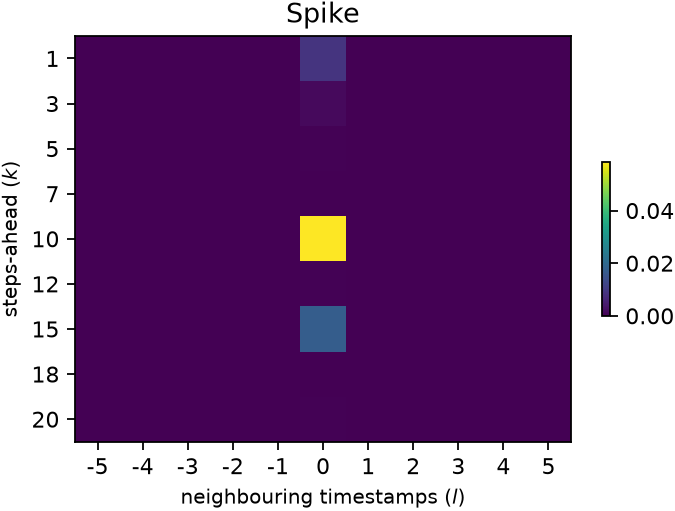

[sigmoid_translation_ad_module_weights.pdf](spike_macro_f1/plots/sigmoid_translation_ad_module_weights.pdf)

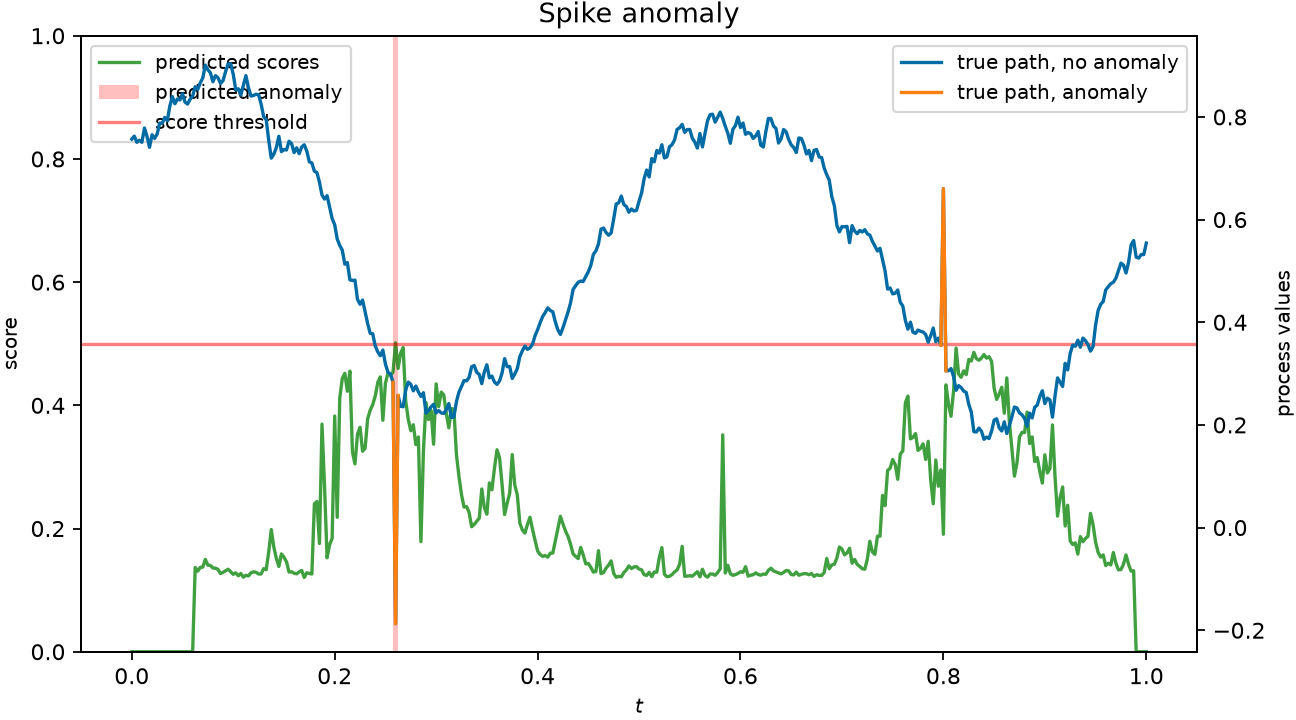

[sigmoid_translation_test_path_0.pdf](spike_macro_f1/plots/sigmoid_translation_test_path_0.pdf)

Test trajectory: 0 spikes in evaluation window: 2
Saved: /Users/fkrach/Code/GitRepos/Probabilistic_forecasting_for_Anomaly_Detection/results/spike_macro_f1/plots/sigmoid_translation_ad_module_weights.pdf
Saved: /Users/fkrach/Code/GitRepos/Probabilistic_forecasting_for_Anomaly_Detection/results/spike_macro_f1/plots/sigmoid_translation_test_path_0.pdf


In [22]:
from IPython.display import display,Image,Markdown
from unittest.mock import patch

PLOT_DIR = OUT / 'plots'
PLOT_DIR.mkdir(exist_ok=True)
PATH_INDEX = 0
assert 0 <= PATH_INDEX < len(test_paths)
assert test_labels[PATH_INDEX,:,time_mask].sum()>0
# Keep the legacy plotter's isinstance check in sync if AD_modules was reloaded in this kernel.
evaluate_AD.AD_module = AD_modules.AD_module
assert isinstance(translated_module,evaluate_AD.AD_module)
plot_path = str(PLOT_DIR)+os.sep

# Save a PNG preview from the same figure while the existing functions save their PDFs.
_original_savefig = plt.savefig
def save_pdf_with_preview(filename,*args,**kwargs):
    _original_savefig(filename,*args,**kwargs)
    if Path(filename).suffix.lower()=='.pdf':
        preview_options = dict(kwargs,dpi=160)
        _original_savefig(Path(filename).with_suffix('.png'),*args,**preview_options)

# The existing heatmap function plots effective sigmoid weights for each horizon and time offset.
with patch.object(plt,'savefig',side_effect=save_pdf_with_preview):
    evaluate_AD.plot_AD_module_params(
        ad_module=translated_module,path=plot_path,filename='sigmoid_translation',
        steps_ahead=HORIZONS,dt=test_meta['dt'],anomaly_type='spike')
WEIGHTS_PDF = PLOT_DIR / 'sigmoid_translation_ad_module_weights.pdf'
assert WEIGHTS_PDF.exists()

# One-item collated batch: local path index 0 corresponds to test trajectory PATH_INDEX.
x = test_paths[PATH_INDEX:PATH_INDEX+1]
y = test_labels[PATH_INDEX:PATH_INDEX+1]
n,dimension,n_steps = x.shape
path_batch = collate([dict(
    stock_path=x,ad_labels=y,observed_dates=np.ones((n,n_steps),dtype=int),
    nb_obs=np.full(n,n_steps-1),dt=test_meta['dt'])])
model.eval()
translated_module.eval()
assert 'get_individual_scores' not in translated_module.__dict__, 'Remove any cached-score override before plotting.'
PATH_PDF = PLOT_DIR / ('sigmoid_translation_test_path_'+str(PATH_INDEX)+'.pdf')
with patch.object(plt,'savefig',side_effect=save_pdf_with_preview):
    evaluate_AD.plot_one_path_with_pred(
        device=torch.device('cpu'),forecast_model=model,ad_module=translated_module,
        batch=path_batch,delta_t=test_meta['dt'],T=test_meta['maturity'],
        paths_to_plot=(0,),save_path=plot_path,filename=PATH_PDF.name,
        plot_variance=False,output_vars=model.output_vars,steps_ahead=HORIZONS,
        plot_forecast_predictions=False,anomaly_type='spike')
assert PATH_PDF.exists()

# Show the previews saved from the same figures as the PDFs.
for pdf_file in [WEIGHTS_PDF,PATH_PDF]:
    preview_file = pdf_file.with_suffix('.png')
    assert preview_file.exists()
    display(Image(filename=str(preview_file)))
    relative_pdf = pdf_file.relative_to(ROOT / 'results').as_posix()
    display(Markdown('['+pdf_file.name+']('+relative_pdf+')'))
print('Test trajectory:',PATH_INDEX,'spikes in evaluation window:',int(y[:,:,time_mask].sum()))
print('Saved:',WEIGHTS_PDF)
print('Saved:',PATH_PDF)


### Additional spike-test paths
Plot three more trajectories with **3, 5, and the maximum available number of labeled spikes** in the common evaluation window. For 3 and 5 spikes, select the first matching trajectory by index; for the maximum, select the first highest-count trajectory. Selection uses labels only, not predicted scores or detection success.

Use the same translated detector and existing evaluate_AD.plot_one_path_with_pred function. Save PDF/PNG pairs alongside path 0, and display each path index and spike count above its notebook preview.


,test_path_index,spikes_in_evaluation_window,spikes_in_full_path
0,1,3,3
1,44,5,5
2,48,7,7


**Test path 1 — 3 labeled spikes in the evaluation window**

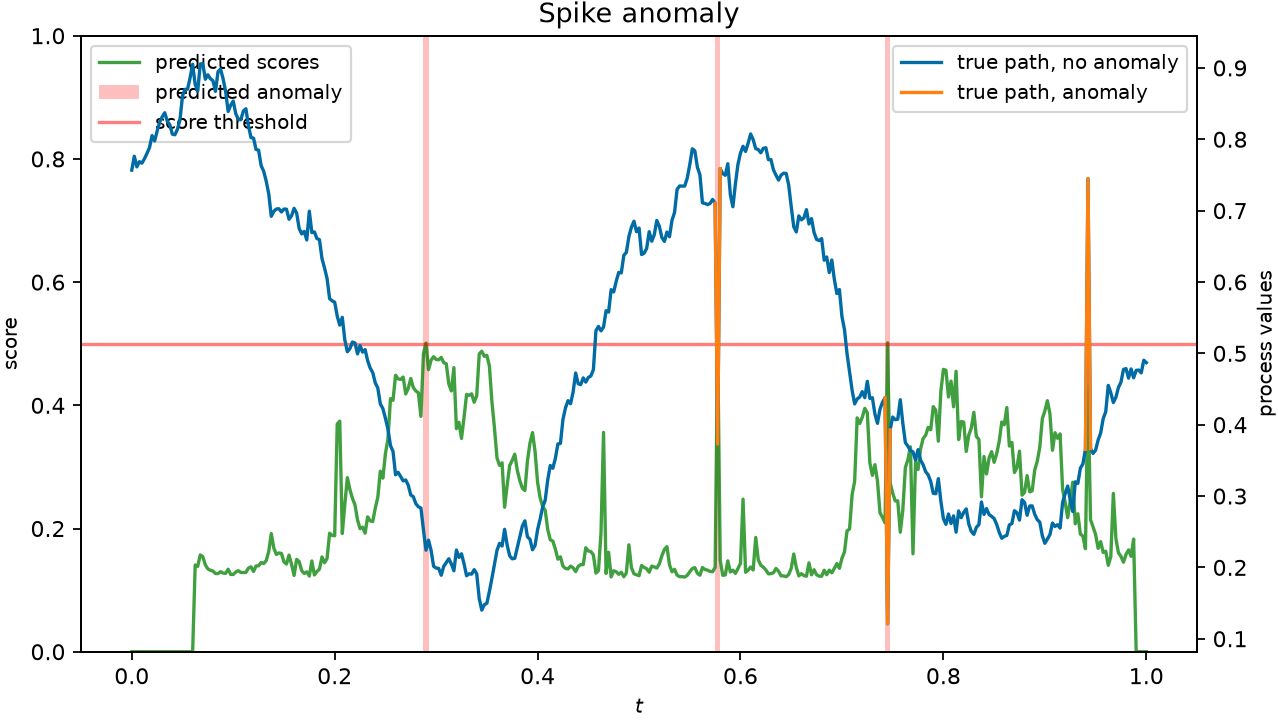

[sigmoid_translation_test_path_1.pdf](spike_macro_f1/plots/sigmoid_translation_test_path_1.pdf)

**Test path 44 — 5 labeled spikes in the evaluation window**

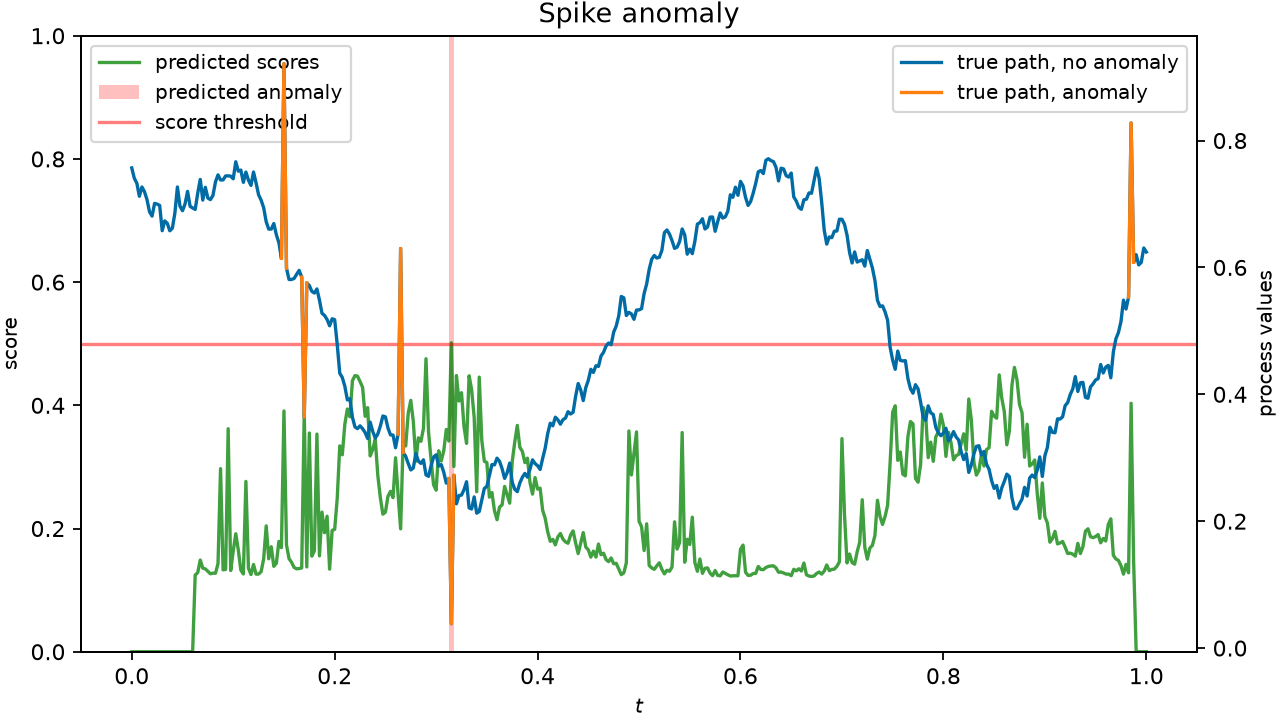

[sigmoid_translation_test_path_44.pdf](spike_macro_f1/plots/sigmoid_translation_test_path_44.pdf)

**Test path 48 — 7 labeled spikes in the evaluation window**

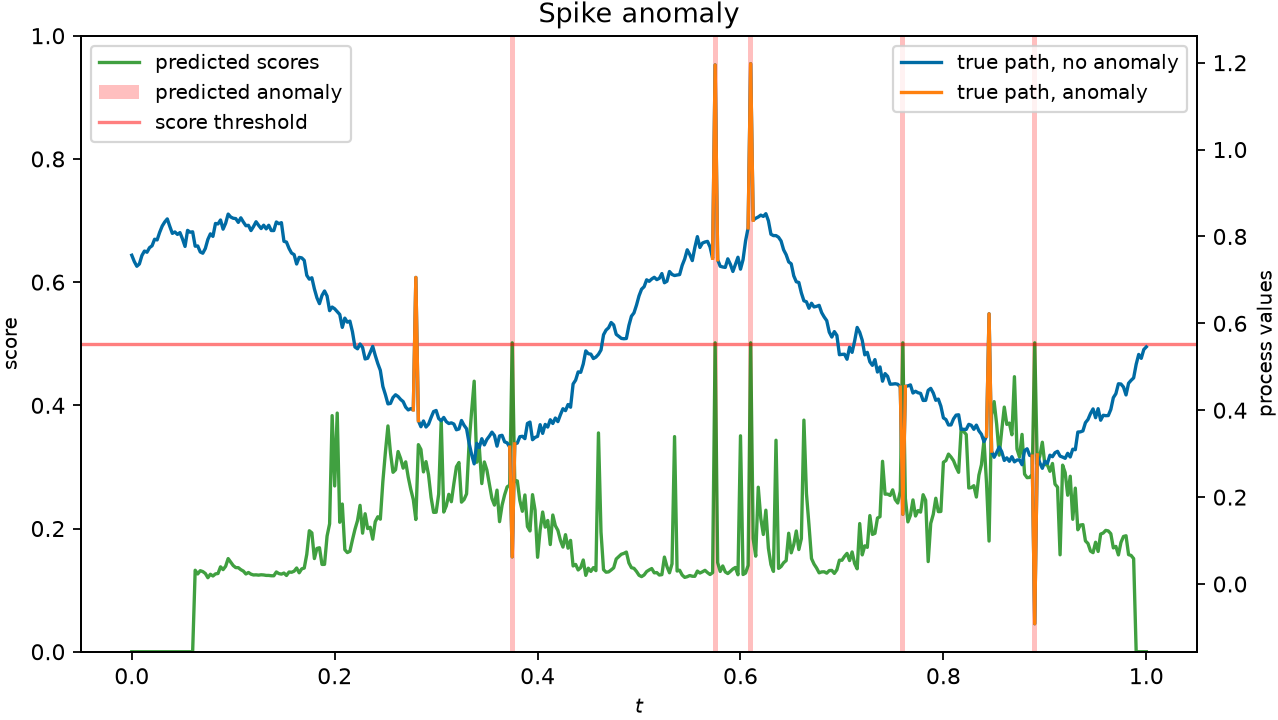

[sigmoid_translation_test_path_48.pdf](spike_macro_f1/plots/sigmoid_translation_test_path_48.pdf)

Additional plots saved to: /Users/fkrach/Code/GitRepos/Probabilistic_forecasting_for_Anomaly_Detection/results/spike_macro_f1/plots


In [23]:
test_spike_counts = test_labels[:,:,time_mask].sum(axis=(1,2)).astype(int)
MORE_PATH_INDICES = [int(np.flatnonzero(test_spike_counts==k)[0]) for k in [3,5]]
MORE_PATH_INDICES.append(int(np.argmax(test_spike_counts)))
assert len(set(MORE_PATH_INDICES))==3
assert np.all(test_spike_counts[MORE_PATH_INDICES]>2)
more_path_selection = pd.DataFrame({
    'test_path_index':MORE_PATH_INDICES,
    'spikes_in_evaluation_window':test_spike_counts[MORE_PATH_INDICES],
    'spikes_in_full_path':test_labels[MORE_PATH_INDICES].sum(axis=(1,2)).astype(int)})
display(more_path_selection)
more_path_selection.to_csv(PLOT_DIR / 'additional_path_selection.csv',index=False)
MORE_PATH_PDFS = []
model.eval()
translated_module.eval()
assert 'get_individual_scores' not in translated_module.__dict__
for path_index in MORE_PATH_INDICES:
    path_values = test_paths[path_index:path_index+1]
    path_labels = test_labels[path_index:path_index+1]
    batch_n,_,batch_steps = path_values.shape
    more_path_batch = collate([dict(
        stock_path=path_values,ad_labels=path_labels,
        observed_dates=np.ones((batch_n,batch_steps),dtype=int),
        nb_obs=np.full(batch_n,batch_steps-1),dt=test_meta['dt'])])
    pdf_file = PLOT_DIR / ('sigmoid_translation_test_path_'+str(path_index)+'.pdf')
    with patch.object(plt,'savefig',side_effect=save_pdf_with_preview):
        evaluate_AD.plot_one_path_with_pred(
            device=torch.device('cpu'),forecast_model=model,ad_module=translated_module,
            batch=more_path_batch,delta_t=test_meta['dt'],T=test_meta['maturity'],
            paths_to_plot=(0,),save_path=plot_path,filename=pdf_file.name,
            plot_variance=False,output_vars=model.output_vars,steps_ahead=HORIZONS,
            plot_forecast_predictions=False,anomaly_type='spike')
    assert pdf_file.exists() and pdf_file.with_suffix('.png').exists()
    MORE_PATH_PDFS.append(pdf_file)
    display(Markdown('**Test path '+str(path_index)+' — '+
                     str(test_spike_counts[path_index])+' labeled spikes in the evaluation window**'))
    display(Image(filename=str(pdf_file.with_suffix('.png'))))
    relative_pdf = pdf_file.relative_to(ROOT / 'results').as_posix()
    display(Markdown('['+pdf_file.name+']('+relative_pdf+')'))
print('Additional plots saved to:',PLOT_DIR)
